# 4. Short-duration XYZ with gaps

## Goal
Estimate the full XYZ spectrum from the **same seven-day realization** with
continuous and gapped observations. A known orbit reference places moving
nulls; a multivariate spline learns its smooth matrix correction.

The short-segment idea is inspired by
[Burke et al., Noisy Pipelines I](https://arxiv.org/html/2610.28726v1).
This controlled matrix simulation is not their complete instrument pipeline.
The fitted residual is frequency-only over the week; the reference carries
time variation. We retain an exact joint-covariance point check after the
fast fit, without fitting secondary noise components.

## Setup
Run notebook 1 first. This lesson reuses its XYZ record and actual observation
windows. The small adapters below prepare library data and initialize a guide;
all multivariate spline inference is still performed by `log_psplines.fit`.

In [1]:
%matplotlib inline
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from log_psplines import fit

from lisa_case_studies.notebook_tools import (
    COLORS,
    matrix_errors,
    reference_config,
    style,
)
from lisa_case_studies.orbit_reference import DAY
from lisa_case_studies.reference_matrix import (
    adaptive_partition,
    coefficient_data,
    elbo_diagnostics,
    matrix_mean,
    pool_log_frequency,
)
from lisa_case_studies.tutorial_data import (
    load_data,
    load_orbit_simulation,
    residual_matrix,
    workspace,
)

style()
data, simulation = load_orbit_simulation()
saved_windows = load_data("windows")
windows = {name: saved_windows[name] for name in ("continuous", "gapped")}

## Step 1 — Keep the original time coordinates
The gap mask removes observations, not elapsed time. A common taper and
separate gap gate determine the two observation operators.

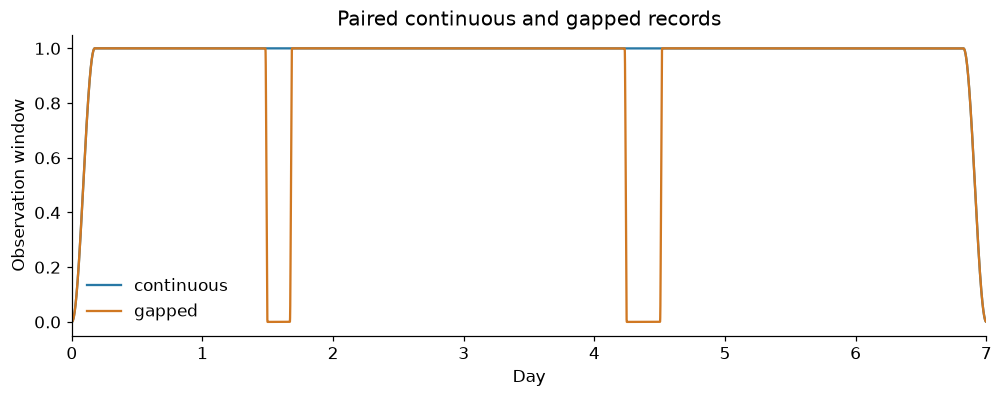

In [2]:
fig, ax = plt.subplots(layout="constrained")
for label, window in windows.items():
    ax.plot(data["time"] / DAY, window, color=COLORS[label], label=label)
ax.set(
    xlabel="Day",
    ylabel="Observation window",
    xlim=(0, 7),
    title="Paired continuous and gapped records",
)
ax.legend(frameon=False)
plt.show()

## Step 2 — Prepare the window-aware matrix reference
For each window, propagate the nominal orbit factors into the **full
same-frequency XYZ covariance** $C_{w,0}(f)$. Whiten native coefficients by
its Cholesky factor before aggregating frequencies.

This preserves channel cross terms. It is still a Whittle approximation to
assume those whitened frequencies are independent. GapLike supplies the
masks/windows; its independent-channel likelihood is not substituted for XYZ.
[More on GapLike and XYZ](../gaplike_xyz.md).

In [3]:
reference = simulation.window_references(windows)
bins = np.flatnonzero(
    (simulation.frequency >= 0.4e-3) & (simulation.frequency <= 99e-3)
)
frequency = simulation.frequency[bins]
inputs = {}
for label, window in windows.items():
    coefficients = np.fft.rfft(data["xyz"] * window[:, None], axis=0)[bins] * np.sqrt(
        2 * simulation.dt / simulation.n
    )
    white = np.linalg.solve(
        np.linalg.cholesky(reference[label][bins]), coefficients[..., None]
    )[..., 0]
    enbw = simulation.n * np.sum(window**2) / np.sum(window) ** 2
    inputs[label] = coefficient_data(white, frequency, enbw=enbw)

## Step 3 — Freeze one adaptive partition
Use only observed gapped training data to select edges, then apply the same
partition to both observations. The pilot selects edges; actual complex
cross-products and their counts are summed without smoothing. Null
neighbourhoods retain native resolution. Bins never change during fitting.

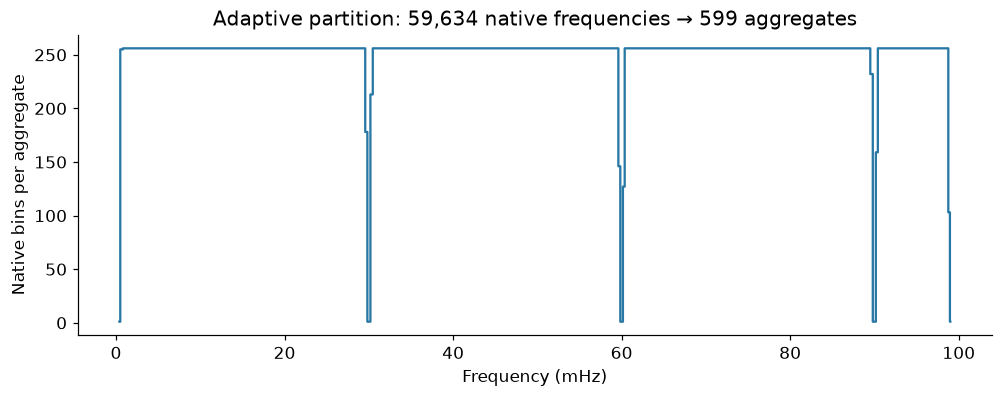

In [4]:
partition = adaptive_partition(inputs["gapped"])
pooled = {
    label: pool_log_frequency(values, partition) for label, values in inputs.items()
}
assert partition.freq_bin_counts.sum() == len(frequency)
fig, ax = plt.subplots(layout="constrained")
ax.step(
    partition.f_coarse * 1000, partition.freq_bin_counts, where="mid", color=COLORS["X"]
)
ax.set(
    xlabel="Frequency (mHz)",
    ylabel="Native bins per aggregate",
    title=f"Adaptive partition: {len(frequency):,} native frequencies → {partition.Nc:,} aggregates",
)
plt.show()

## Step 4 — Fit a full multivariate correction
The physical model is $S(t,f)=L_0(t,f)R(f)L_0(t,f)^\dagger$ with a full
positive-definite spline matrix $R$. The library analytically integrates the
six Gaussian theta fields and restores their conditional draws afterward.
This integration is exact **for the chosen Whittle model**, not for the
joint gapped likelihood.

Use the same prior and basis for both observations, and three independently
seeded VI restarts. The guide starts near the known reference to avoid
rank-one empirical initialisation. Only training ELBO selects a restart.

In [5]:
base_config, components = reference_config(pooled["gapped"], steps=4000, draws=96)
candidates = {}
for label in windows:
    candidates[label] = []
    for restart in range(3):
        config = replace(base_config, rng_key=207 + restart)
        candidates[label].append(fit(pooled[label], config))
selected = {
    label: min(items, key=lambda r: float(np.asarray(r.vi.losses)[-8:].mean()))
    for label, items in candidates.items()
}

W1106 12:13:04.963393 2373144 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.


## Step 5 — Check optimisation before looking at truth
Loss plateaus and restart agreement are numerical checks. They do not imply
NUTS-equivalent uncertainty, especially with correlated Fourier features.

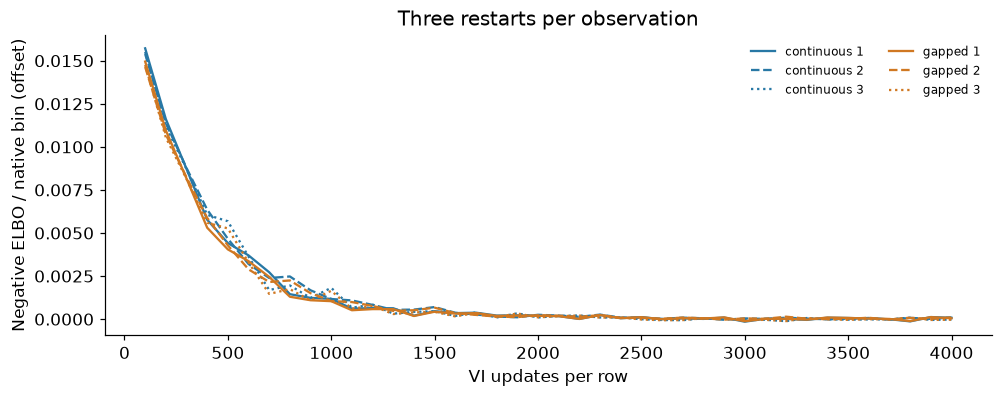

,Observation,Restart,Largest tail change / native bin
0,continuous,1,0.000023
1,continuous,2,0.000023
2,continuous,3,0.000049
3,gapped,1,0.000015
4,gapped,2,0.000019
5,gapped,3,0.000054


In [6]:
checks = []
fig, ax = plt.subplots(layout="constrained")
for label, items in candidates.items():
    offset = min(float(np.asarray(r.vi.losses)[-8:].mean()) for r in items)
    for restart, result in enumerate(items):
        assert result.metadata["theta_parameterization"] == "marginalized"
        rows = [
            elbo_diagnostics(loss, len(frequency))
            for loss in result.vi.losses_per_block
        ]
        checks.append(
            {
                "Observation": label,
                "Restart": restart + 1,
                "Largest tail change / native bin": max(
                    row["tail_mean_change_per_native_bin"] for row in rows
                ),
            }
        )
        loss = np.asarray(result.vi.losses)
        ax.plot(
            np.linspace(100, base_config.vi_steps, len(loss)),
            (loss - offset) / len(frequency),
            color=COLORS[label],
            ls=("-", "--", ":")[restart],
            label=f"{label} {restart + 1}",
        )
ax.set(
    xlabel="VI updates per row",
    ylabel="Negative ELBO / native bin (offset)",
    title="Three restarts per observation",
)
ax.legend(ncol=2, fontsize=8, frameon=False)
plt.show()
pd.DataFrame(checks).round(6)

## Step 6 — Recover the physical XYZ spectral matrix
Undo the reference transformation on a fixed native-frequency evaluation
support. Reconstruction uses restored theta draws, and averages complete
positive-definite matrices. Truth is used only from this point onward.

In [7]:
probe = np.unique(
    np.r_[
        np.rint(np.geomspace(0.4e-3, 99e-3, 400) * simulation.n * simulation.dt).astype(
            int
        ),
        *[
            np.flatnonzero(np.abs(simulation.frequency - f0) < 0.6e-3)
            for f0 in (0.03, 0.06, 0.09)
        ],
    ]
)
evaluation_frequency = simulation.frequency[probe]
evaluation_time = np.linspace(0, data["time"][-1], 17)
coordinate = np.clip(
    np.log(evaluation_frequency / frequency[0]) / np.log(frequency[-1] / frequency[0]),
    0,
    1,
)
factor = simulation.reference_factor(evaluation_time, evaluation_frequency)
truth = simulation.spectrum(evaluation_time, evaluation_frequency)
estimates = {}
for label, result in selected.items():
    correction = matrix_mean(result.posterior, components, coordinate)
    estimates[label] = factor @ correction[None] @ factor.conj().swapaxes(-1, -2)

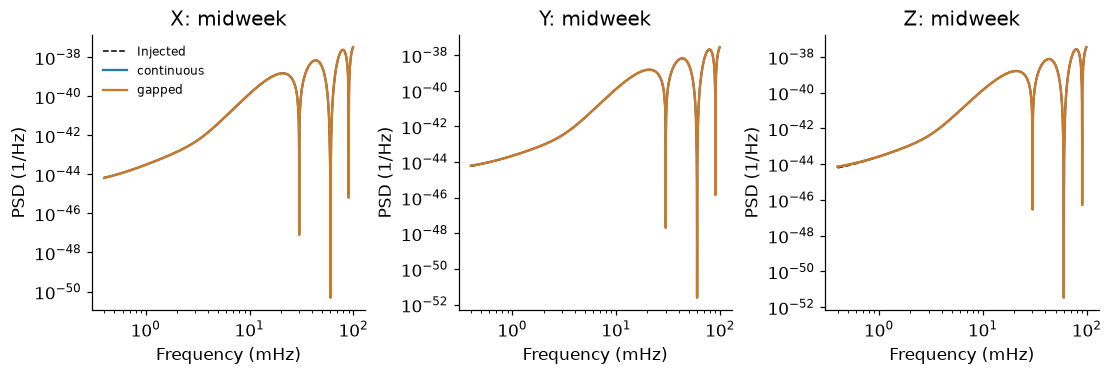

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), layout="constrained")
for j, (ax, channel) in enumerate(zip(axes, "XYZ", strict=True)):
    ax.loglog(
        evaluation_frequency * 1000,
        truth[8, :, j, j].real,
        "k--",
        lw=1,
        label="Injected",
    )
    for label, estimate in estimates.items():
        ax.loglog(
            evaluation_frequency * 1000,
            estimate[8, :, j, j].real,
            color=COLORS[label],
            label=label,
        )
    ax.set(xlabel="Frequency (mHz)", ylabel="PSD (1/Hz)", title=f"{channel}: midweek")
axes[0].legend(fontsize=8, frameon=False)
plt.show()

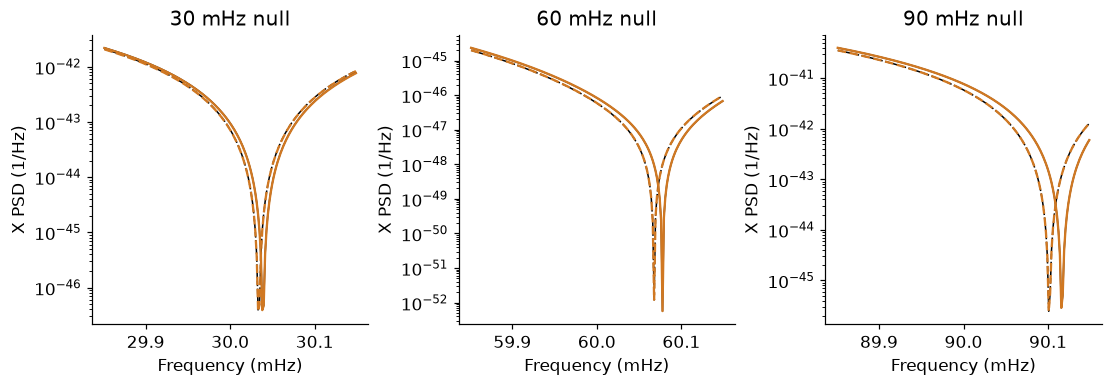

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), layout="constrained")
for ax, f0 in zip(axes, (0.03, 0.06, 0.09), strict=True):
    keep = np.abs(evaluation_frequency - f0) < 0.15e-3
    for t, ls in ((0, "--"), (-1, "-")):
        ax.semilogy(
            evaluation_frequency[keep] * 1000,
            truth[t, keep, 0, 0].real,
            color="k",
            ls=ls,
            lw=1,
        )
        ax.semilogy(
            evaluation_frequency[keep] * 1000,
            estimates["gapped"][t, keep, 0, 0].real,
            color=COLORS["gapped"],
            ls=ls,
        )
    ax.set(
        xlabel="Frequency (mHz)",
        ylabel="X PSD (1/Hz)",
        title=f"{f0 * 1000:.0f} mHz null",
    )
plt.show()

Black is injected; orange is the gapped reconstruction. Dashed curves show
day 0 and solid curves day 7. Geometry supplies the dip motion; smooth
splines do not have to discover the nulls unaided.

In [10]:
error_table = pd.DataFrame(
    {label: matrix_errors(estimate, truth) for label, estimate in estimates.items()}
).T
error_table.round(4)

,Auto log10 RMSE,Complex cross RMSE
continuous,0.0053,0.0115
gapped,0.0054,0.0116


## Step 7 — Keep an exact covariance benchmark
Take a small **fixed** set of adjacent native bins around each null. For
these retained XYZ features, the simulator can calculate the full joint
real Gaussian covariance, including frequency coupling and pseudo-covariance.
This is exact for this declared matrix simulator, not for the full time record.
It evaluates point reconstructions; it does not fit or marginalise theta
under the joint likelihood.

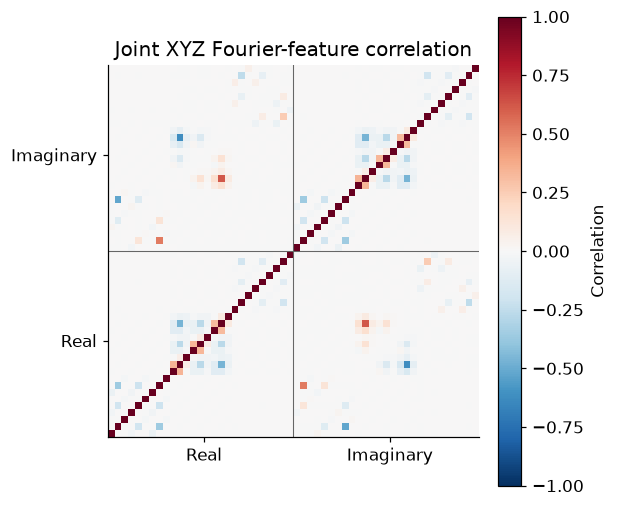

In [11]:
selected_bins = np.unique(
    (
        np.rint(np.array([0.03, 0.06, 0.09]) * simulation.n * simulation.dt).astype(
            int
        )[:, None]
        + np.array([-1, 0, 1])[None]
    ).ravel()
)
window = windows["gapped"]
nominal_covariance = simulation.feature_covariance(window, selected_bins)
std = np.sqrt(np.diag(nominal_covariance))
correlation = nominal_covariance / np.outer(std, std)
fig, ax = plt.subplots(figsize=(5.5, 4.5), layout="constrained")
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="RdBu_r", origin="lower")
half = len(correlation) // 2
ax.axvline(half - 0.5, color="0.4", lw=0.7)
ax.axhline(half - 0.5, color="0.4", lw=0.7)
ax.set(
    xticks=[half / 2, 1.5 * half],
    yticks=[half / 2, 1.5 * half],
    xticklabels=["Real", "Imaginary"],
    yticklabels=["Real", "Imaginary"],
    title="Joint XYZ Fourier-feature correlation",
)
fig.colorbar(image, ax=ax, label="Correlation")
plt.show()

Off-diagonal frequency blocks are the information discarded by the fast
Whittle fit. The matrix also retains within-frequency XYZ correlations.
Use four independent realizations for the following point check. The
injected-matrix row is an oracle control, never a model-selection input.
Outside the fitted frequency band, the recovered residual is extended
constantly at its nearest boundary; this assumption is explicit in the score.

In [12]:
full_coordinate = np.clip(
    np.log(simulation.frequency[1:] / frequency[0])
    / np.log(frequency[-1] / frequency[0]),
    0,
    1,
)
fitted_residual = matrix_mean(selected["gapped"].posterior, components, full_coordinate)
covariances = {
    "Reference only": nominal_covariance,
    "Gapped spline point": simulation.feature_covariance(
        window, selected_bins, correction=fitted_residual
    ),
    "Injected matrix (oracle)": simulation.feature_covariance(
        window, selected_bins, correction=residual_matrix(simulation.frequency[1:])
    ),
}
whitening = np.linalg.inv(np.linalg.cholesky(nominal_covariance))
validation = (
    np.asarray(
        [
            simulation.features(simulation.draw(seed), window, selected_bins)
            for seed in range(1007, 1011)
        ]
    )
    @ whitening.T
)
joint_scores = []
for label, covariance in covariances.items():
    covariance = whitening @ covariance @ whitening.T
    q = np.einsum("ri,ir->r", validation, np.linalg.solve(covariance, validation.T))
    joint_scores.append(
        {
            "Point model": label,
            "Mean exact joint q / dimension": q.mean() / covariance.shape[0],
        }
    )
pd.DataFrame(joint_scores).round(3)

,Point model,Mean exact joint q / dimension
0,Reference only,0.962
1,Gapped spline point,0.964
2,Injected matrix (oracle),0.966


## Checks and next steps
A joint quadratic near one is an independent point-model check, not proof
of posterior coverage. The main inference remains an approximate Whittle
fit. The reference, partition, priors and restarts were fixed before the
independent validation records were generated.

For the full derivation, see the [simulation notes](../notebook_models.md)
and [GapLike/XYZ explanation](../gaplike_xyz.md).

In [13]:
assert np.isfinite(truth).all()
for label, estimate in estimates.items():
    assert np.isfinite(estimate).all()
    assert (
        len(
            [
                name
                for name in selected[label].posterior
                if name.startswith("weights_theta_")
            ]
        )
        == 6
    )
np.savez_compressed(
    workspace() / "short_xyz_recovery.npz",
    frequency=evaluation_frequency,
    time=evaluation_time,
    truth=truth,
    continuous=estimates["continuous"],
    gapped=estimates["gapped"],
    bin_starts=partition.J_start,
    bin_stops=partition.J_stop,
    bin_counts=partition.freq_bin_counts,
)
error_table.to_json(workspace() / "short_xyz_errors.json", orient="index", indent=2)